# 06 — Pelatihan SVM
`Pipeline([StandardScaler, SVC(class_weight="balanced")])`

Alur (test set disentuh **sekali saja**, di langkah 4):
1. **Tuning** hiperparameter: fit di *train*, dinilai di *validasi* (macro-F1)
2. **Cross-validation 5 lipat** (stratified) di train+val dengan parameter terbaik → estimasi kestabilan
3. **Model final** dilatih ulang di **train + val**
4. **Evaluasi test sekali** + classification report + confusion matrix
5. **Ablasi fitur** (warna saja, GLCM saja, gabungan, +bentuk) — memakai CV di train+val, bukan test, supaya test tetap bersih

In [1]:
from pathlib import Path
import json, random
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from IPython.display import display
try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **k: x

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# Root proyek = folder pcv_bkpm (otomatis, baik dijalankan dari notebooks/ maupun root)
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = ROOT / "dataset_crop"      # input: citra daun hasil crop, 1 subfolder = 1 kelas
OUT  = ROOT / "output"            # semua hasil notebook disimpan di sini
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
CLASSES = sorted(p.name for p in DATA.iterdir() if p.is_dir())   # label = nama subfolder

def imread(path, flags=cv2.IMREAD_COLOR):          # aman untuk path Windows ber-spasi/non-ASCII
    return cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), flags)

def imwrite(path, img):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    ok, buf = cv2.imencode(path.suffix, img); buf.tofile(str(path)); return ok

def list_images(folder):
    return sorted(p for p in Path(folder).iterdir() if p.suffix.lower() in IMG_EXT)

def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print("ROOT   :", ROOT)
print("Kelas  :", CLASSES)

ROOT   : D:\SEMESTER 5\pcv_bkpm
Kelas  : ['bercak_daun', 'sehat', 'ulat', 'virus_gemini']


c:\Users\Shobri\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import joblib
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import ParameterGrid, StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)

df = pd.read_csv(OUT / "split.csv")
groups = json.loads((OUT / "feature_groups.json").read_text())
label_map = json.loads((OUT / "label_map.json").read_text())
names = [k for k, _ in sorted(label_map.items(), key=lambda kv: kv[1])]

FEATURES = groups["warna"] + groups["glcm"]            # 22 fitur inti
tr, va, te = (df[df.split == s] for s in ["train", "val", "test"])
trva = df[df.split.isin(["train", "val"])]
print(f"Fitur: {len(FEATURES)} | train {len(tr)} | val {len(va)} | test {len(te)} | kelas: {names}")

def make_pipe(**params):
    pipe = Pipeline([("scaler", StandardScaler()), ("svm", SVC(class_weight="balanced", random_state=SEED))])
    return pipe.set_params(**params)

Fitur: 22 | train 168 | val 36 | test 36 | kelas: ['bercak_daun', 'sehat', 'ulat', 'virus_gemini']


## 1. Tuning di validasi

In [3]:
GRID = [
    {"svm__kernel": ["rbf"], "svm__C": [0.1, 1, 10, 100, 1000], "svm__gamma": ["scale", 0.1, 0.03, 0.01, 0.003, 0.001]},
    {"svm__kernel": ["linear"], "svm__C": [0.01, 0.1, 1, 10, 100]},
]
res = []
for params in tqdm(list(ParameterGrid(GRID)), desc="tuning"):
    pipe = make_pipe(**params).fit(tr[FEATURES], tr.label_id)
    pred = pipe.predict(va[FEATURES])
    res.append({**params, "val_acc": accuracy_score(va.label_id, pred),
                "val_f1_macro": f1_score(va.label_id, pred, average="macro")})
df_tune = pd.DataFrame(res).sort_values(["val_f1_macro", "val_acc"], ascending=False).reset_index(drop=True)
display(df_tune.head(10).round(4))

BEST = {k: v for k, v in df_tune.iloc[0].items() if k.startswith("svm__") and not pd.isna(v)}
print("Parameter terbaik:", BEST)

tuning: 100%|██████████| 35/35 [00:01<00:00, 23.01it/s]


,svm__C,svm__gamma,svm__kernel,val_acc,val_f1_macro
0,1.0,scale,rbf,0.6111,0.5810
1,10.0,0.01,rbf,0.5833,0.5606
2,1.0,0.01,rbf,0.6111,0.5571
3,1.0,0.03,rbf,0.5833,0.5482
4,10.0,0.1,rbf,0.5556,0.5473
5,1000.0,0.001,rbf,0.5556,0.5404
6,10.0,NaN,linear,0.5556,0.5347
7,10.0,scale,rbf,0.5556,0.5333
8,0.1,NaN,linear,0.5833,0.5317
9,1.0,NaN,linear,0.5278,0.5261


Parameter terbaik: {'svm__C': np.float64(1.0), 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}


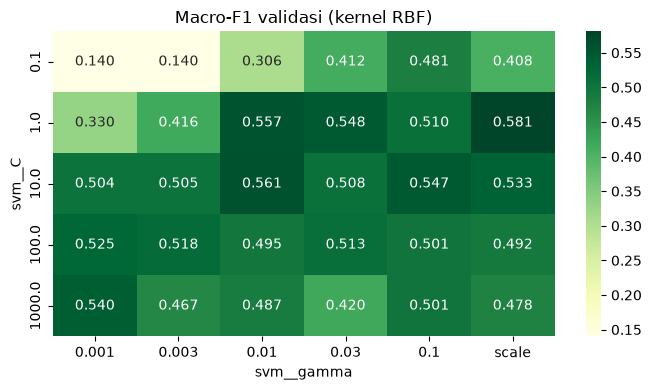

In [4]:
rbf = df_tune[df_tune.svm__kernel == "rbf"].copy()
rbf["svm__gamma"] = rbf["svm__gamma"].astype(str)
pv = rbf.pivot_table(index="svm__C", columns="svm__gamma", values="val_f1_macro")
import seaborn as sns
plt.figure(figsize=(7, 4)); sns.heatmap(pv, annot=True, fmt=".3f", cmap="YlGn")
plt.title("Macro-F1 validasi (kernel RBF)"); plt.tight_layout(); plt.show()

## 2. Cross-validation 5 lipat (train + val)

In [5]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv = cross_validate(make_pipe(**BEST), trva[FEATURES], trva.label_id, cv=skf,
                    scoring=["accuracy", "f1_macro"], return_train_score=True)
df_cv = pd.DataFrame({"fold": range(1, 6), "acc_train": cv["train_accuracy"], "acc_val": cv["test_accuracy"],
                      "f1_macro_val": cv["test_f1_macro"]}).round(4)
display(df_cv)
print(f"Akurasi CV : {cv['test_accuracy'].mean():.4f} ± {cv['test_accuracy'].std():.4f}")
print(f"Macro-F1 CV: {cv['test_f1_macro'].mean():.4f} ± {cv['test_f1_macro'].std():.4f}")

,fold,acc_train,acc_val,f1_macro_val
0,1,0.7607,0.4878,0.4720
1,2,0.7117,0.5854,0.5835
2,3,0.7055,0.5610,0.5496
3,4,0.6994,0.5854,0.5721
4,5,0.7256,0.6000,0.5692


Akurasi CV : 0.5639 ± 0.0401
Macro-F1 CV: 0.5493 ± 0.0401


## 3. Model final (train + val)

In [6]:
final_model = make_pipe(**BEST).fit(trva[FEATURES], trva.label_id)
OUT_MODEL = OUT / "model"; OUT_MODEL.mkdir(exist_ok=True)
joblib.dump({"model": final_model, "features": FEATURES, "label_map": label_map, "params": BEST}, OUT_MODEL / "svm_final.joblib")
print("Model dilatih pada", len(trva), "sampel (train+val). Tersimpan di", OUT_MODEL / "svm_final.joblib")
print(final_model)

Model dilatih pada 204 sampel (train+val). Tersimpan di D:\SEMESTER 5\pcv_bkpm\output\model\svm_final.joblib
Pipeline(steps=[('scaler', StandardScaler()),
                ('svm',
                 SVC(C=np.float64(1.0), class_weight='balanced',
                     random_state=42))])


## 4. Evaluasi test (sekali saja)

In [7]:
pred_te = final_model.predict(te[FEATURES])
print(f"Akurasi test : {accuracy_score(te.label_id, pred_te):.4f}")
print(f"Macro-F1 test: {f1_score(te.label_id, pred_te, average='macro'):.4f}\n")
print(classification_report(te.label_id, pred_te, target_names=names, digits=4))
pd.DataFrame(classification_report(te.label_id, pred_te, target_names=names, output_dict=True)).T.to_csv(OUT_MODEL / "classification_report_test.csv")

Akurasi test : 0.4722
Macro-F1 test: 0.4519

              precision    recall  f1-score   support

 bercak_daun     0.4615    0.7500    0.5714         8
       sehat     0.5714    0.5714    0.5714         7
        ulat     0.1667    0.1250    0.1429         8
virus_gemini     0.6000    0.4615    0.5217        13

    accuracy                         0.4722        36
   macro avg     0.4499    0.4770    0.4519        36
weighted avg     0.4674    0.4722    0.4582        36



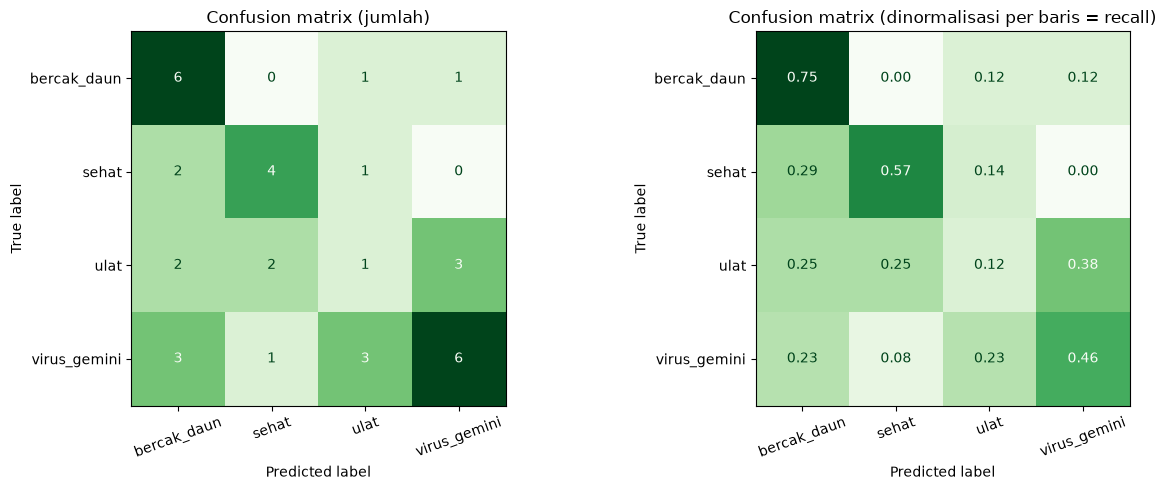

In [8]:
cm = confusion_matrix(te.label_id, pred_te, labels=range(len(names)))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(cm, display_labels=names).plot(ax=axes[0], cmap="Greens", colorbar=False, xticks_rotation=20)
axes[0].set_title("Confusion matrix (jumlah)")
ConfusionMatrixDisplay(confusion_matrix(te.label_id, pred_te, labels=range(len(names)), normalize="true"),
                       display_labels=names).plot(ax=axes[1], cmap="Greens", colorbar=False, xticks_rotation=20, values_format=".2f")
axes[1].set_title("Confusion matrix (dinormalisasi per baris = recall)")
plt.tight_layout(); fig.savefig(OUT_MODEL / "confusion_matrix_test.png", dpi=150); plt.show()

## 5. Ablasi fitur
Parameter SVM dikunci ke `BEST`; tiap kombinasi fitur dinilai dengan CV 5 lipat di train+val (test tidak disentuh).

,set fitur,acc_mean,acc_std,f1_macro_mean,f1_macro_std
0,Warna HSV (6),0.4855,0.0412,0.4889,0.0433
1,GLCM (16),0.4856,0.0429,0.4336,0.0365
2,Warna + GLCM (22),0.5639,0.0401,0.5493,0.0401
3,Warna + GLCM + Bentuk (26),0.5594,0.0931,0.5455,0.0818
4,Bentuk saja (4),0.4465,0.0707,0.4058,0.0819


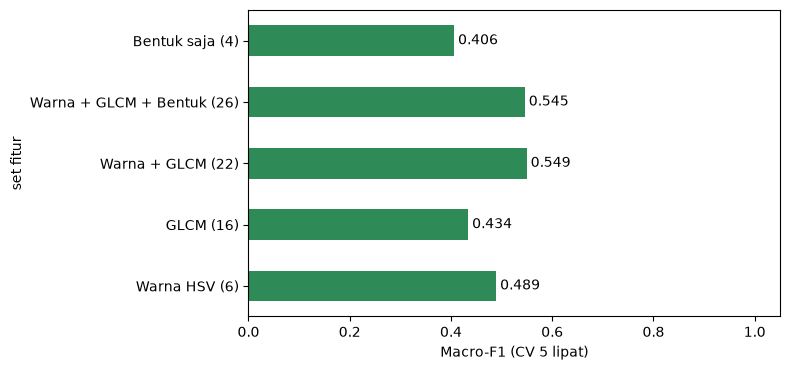

In [9]:
SETS = {
    "Warna HSV (6)": groups["warna"],
    "GLCM (16)": groups["glcm"],
    "Warna + GLCM (22)": groups["warna"] + groups["glcm"],
    "Warna + GLCM + Bentuk (26)": groups["warna"] + groups["glcm"] + groups["bentuk"],
    "Bentuk saja (4)": groups["bentuk"],
}
rows = []
for name, cols in SETS.items():
    r = cross_validate(make_pipe(**BEST), trva[cols], trva.label_id, cv=skf, scoring=["accuracy", "f1_macro"])
    rows.append({"set fitur": name, "acc_mean": r["test_accuracy"].mean(), "acc_std": r["test_accuracy"].std(),
                 "f1_macro_mean": r["test_f1_macro"].mean(), "f1_macro_std": r["test_f1_macro"].std()})
df_abl = pd.DataFrame(rows).round(4)
display(df_abl)

ax = df_abl.plot.barh(x="set fitur", y="f1_macro_mean", xerr=df_abl.f1_macro_std, legend=False, figsize=(8, 3.8), color="seagreen")
ax.bar_label(ax.containers[1] if len(ax.containers) > 1 else ax.containers[0], fmt="%.3f", padding=3)
ax.set_xlabel("Macro-F1 (CV 5 lipat)"); ax.set_xlim(0, 1.05); plt.tight_layout(); plt.show()
df_abl.to_csv(OUT_MODEL / "ablasi_fitur.csv", index=False)